# MLPClassifier — Previsão de churn

Este notebook tem como objetivo treinar uma rede neural simples com o MLPClassifier do Scikit-Learn para prever o churn de clientes. O modelo será comparado com a Regressão Logística e a Random Forest, utilizando as mesmas features e a mesma divisão treino/teste.

## 1. Objetivos

- Preparar as variáveis categóricas e padronizar as numéricas;
- Treinar um MLP com uma camada oculta;
- Calcular as métricas de classificação, com foco no F1-score da classe churn;
- Comparar o desempenho com os outros modelos;
- Registrar os resultados e as limitações desta configuração inicial.

## 2. Importações

In [1]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
import matplotlib.pyplot as plt
import pandas as pd

RANDOM_STATE = 42
TARGET = "Churn Value"

## 3. Carregamento dos dados

In [2]:
df = pd.read_parquet("../data/processed/dataset.parquet")

print(f"Dimensões: {df.shape}")
df.head()

Dimensões: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


## 4. Separação entre features e target

In [3]:
columns_to_drop = [
    TARGET,
    "CustomerID",
    "Churn Label",
    "Churn Score",
    "Churn Reason",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
]

columns_to_drop = [
    column for column in columns_to_drop
    if column in df.columns
]

X = df.drop(columns=columns_to_drop)
y = df[TARGET].astype(int)

print(f"Features: {X.shape}")
print(f"Target: {y.shape}")

Features: (7043, 20)
Target: (7043,)


## 5. Divisão em treino e teste

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Treino: {X_train.shape}")
print(f"Teste: {X_test.shape}")

Treino: (5634, 20)
Teste: (1409, 20)


## 6. Pré-processamento

In [5]:
numeric_columns = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    )),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_columns),
    ("categorical", categorical_preprocessor, categorical_columns),
])

## 7. Treinamento

In [6]:
mlp_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32,),
        activation="relu",
        solver="adam",
        alpha=0.001,
        max_iter=300,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42,
    )),
])

mlp_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Gender','Senior Citizen','Partner',...,'Monthly Charges','Total Charges', 'CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

## 8. Métricas

,MLPClassifier
Accuracy,0.7949
Precision,0.6460
Recall,0.5027
F1-score,0.5654
ROC-AUC,0.8376


              precision    recall  f1-score   support

   Não churn       0.83      0.90      0.87      1035
       Churn       0.65      0.50      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.79      1409



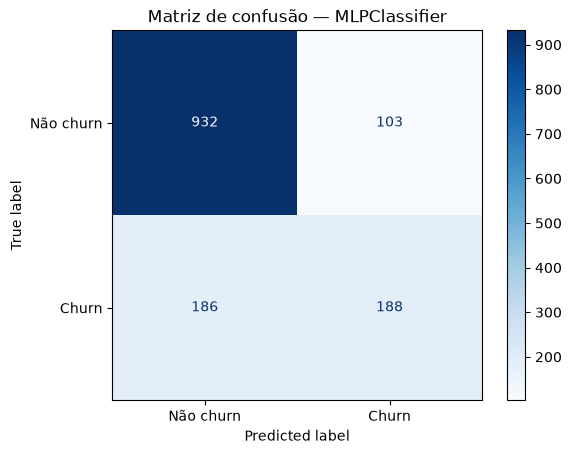

In [7]:
y_pred = mlp_model.predict(X_test)
y_pred_proba = mlp_model.predict_proba(X_test)[:, 1]

mlp_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_pred_proba),
}, name="MLPClassifier")

display(mlp_metrics.to_frame().style.format("{:.4f}"))

print(classification_report(
    y_test,
    y_pred,
    target_names=["Não churn", "Churn"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Não churn", "Churn"],
    cmap="Blues",
)
plt.title("Matriz de confusão — MLPClassifier")
plt.show()

In [8]:
trained_mlp = mlp_model.named_steps["classifier"]

print(f"Épocas executadas: {trained_mlp.n_iter_}")
print(f"Loss final: {trained_mlp.loss_:.4f}")

Épocas executadas: 19
Loss final: 0.3944


## 9. Comparação com os resultados obtidos com Logistic Regression e Random Forest

In [9]:
comparison = pd.DataFrame({
    "Regressão Logística": {
        "Accuracy": 0.8034,
        "Precision": 0.6456,
        "Recall": 0.5749,
        "F1-score": 0.6082,
        "ROC-AUC": 0.8488,
    },
    "Random Forest": {
        "Accuracy": 0.7942,
        "Precision": 0.6400,
        "Recall": 0.5134,
        "F1-score": 0.5697,
        "ROC-AUC": 0.8383,
    },
    "MLPClassifier": mlp_metrics,
})

display(comparison.style.format("{:.4f}"))

,Regressão Logística,Random Forest,MLPClassifier
Accuracy,0.8034,0.7942,0.7949
Precision,0.6456,0.6400,0.6460
Recall,0.5749,0.5134,0.5027
F1-score,0.6082,0.5697,0.5654
ROC-AUC,0.8488,0.8383,0.8376


## Conclusão

O MLPClassifier, configurado com uma camada oculta de 32 neurônios, obteve F1-score de **0,5654**, recall de **0,5027** e ROC-AUC de **0,8376** para a previsão de churn. O treinamento foi encerrado após 19 épocas com o uso de parada antecipada.

Nesta configuração inicial, o MLP apresentou F1-score inferior ao da Regressão Logística (**0,6082**) e ao da Random Forest (**0,5697**). Seu recall também foi o menor entre os três modelos, indicando maior dificuldade em identificar clientes que efetivamente cancelaram.

Assim, a Regressão Logística permanece como referência nesta comparação inicial. O desempenho do MLP poderá ser investigado posteriormente por meio de validação cruzada e ajustes de arquitetura e hiperparâmetros realizados apenas com os dados de treino.